# CMSC 478: Introduction to Machine Learning


# Decision Tree Classification
## Classification of iris flowers

## Background Section

We will be using the Scikit-learn (sklearn) Python library to explore using a Decision Tree (DT) for classifying iris flowers by common morphological features.

## Scikit-Learn Iris Dataset

The sklearn iris dataset consists of 150 samples of 3 different types of iris flowers (Setosa, Versicolour, and Virginica), with each sample is associated with 4 features based on the sepal and petal dimensions. The data is stored in a $150\times 4$ array where rows are the samples and the columns are:
sepal Length
sepal Width
petal Length
petal Width

This dataset has been labelled, meaning human(s) reviewed the samples and manually classified them. These labels are the ground truth and will be used to test the predictions of the classifier.

## Classifiying iris flowers

1. import libraries.
2. load dataset.

$
\renewcommand\vec{\mathbf}
$

In [ ]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.datasets import load_iris
from sklearn import tree
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

### Explore the dataset

Load the iris dataset.

In [ ]:
iris = load_iris()

The dataset is stored as a Python dictionary object.

The data and target values are stored as NumPy arrays.

The data attribute contains the samples, i.e. observations, and the target attribute contains the class labels.

Print out all the keys.

In [ ]:
iris.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

A description of the dataset can be printed using the DESCR key.

In [ ]:
iris.DESCR

'.. _iris_dataset:\n\nIris plants dataset\n--------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 150 (50 in each of three classes)\n:Number of Attributes: 4 numeric, predictive attributes and the class\n:Attribute Information:\n    - sepal length in cm\n    - sepal width in cm\n    - petal length in cm\n    - petal width in cm\n    - class:\n            - Iris-Setosa\n            - Iris-Versicolour\n            - Iris-Virginica\n\n:Summary Statistics:\n\n============== ==== ==== ======= ===== ====================\n                Min  Max   Mean    SD   Class Correlation\n============== ==== ==== ======= ===== ====================\nsepal length:   4.3  7.9   5.84   0.83    0.7826\nsepal width:    2.0  4.4   3.05   0.43   -0.4194\npetal length:   1.0  6.9   3.76   1.76    0.9490  (high!)\npetal width:    0.1  2.5   1.20   0.76    0.9565  (high!)\n============== ==== ==== ======= ===== ====================\n\n:Missing Attribute Values: None\n:Class Distribution: 

Print out the shape of the data and verify it has dimensions $150\times 4$.

In [ ]:
print("shape      = ", iris.data.shape)
print("dimensions = ", len(iris.data.shape))

shape      =  (150, 4)
dimensions =  2


Print out the shape and number of dimensions of the target.

In [ ]:
print("shape      = ", iris.target.shape)
print("dimensions = ", len(iris.target.shape))

shape      =  (150,)
dimensions =  1


Let's look at the feature names and verify they are:
sepal length,
sepal weight,
petal length,
petal width

In [ ]:
print("features = ", iris.feature_names)

features =  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Now let's print the target names, i.e. classes, to verify the names of the iris species.

In [ ]:
print("targets = ", iris.target_names)

targets =  ['setosa' 'versicolor' 'virginica']


There are only three possible classes (labels).

Verify there are only three labels in the data.

In [ ]:
np.unique(iris.target)

array([0, 1, 2])

Each sample (row) in the data is a feature vector. These are the independent variables obtained from measurements.

The dependent variable is the class label. In this case, the classes are the three iris species.

Print a random sample of rows.

In [ ]:
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris['target']
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.sample(10, random_state=1)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
14,5.8,4.0,1.2,0.2,0,setosa
98,5.1,2.5,3.0,1.1,1,versicolor
75,6.6,3.0,4.4,1.4,1,versicolor
16,5.4,3.9,1.3,0.4,0,setosa
131,7.9,3.8,6.4,2.0,2,virginica
56,6.3,3.3,4.7,1.6,1,versicolor
141,6.9,3.1,5.1,2.3,2,virginica
44,5.1,3.8,1.9,0.4,0,setosa
29,4.7,3.2,1.6,0.2,0,setosa
120,6.9,3.2,5.7,2.3,2,virginica


Let's look at a plot of the data.

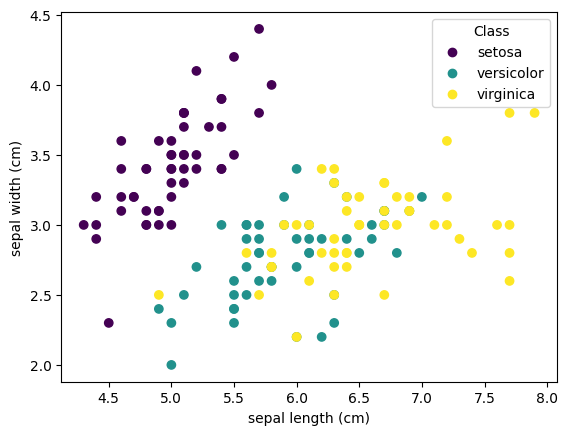

In [ ]:
fig, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
fig = ax.legend(
    scatter.legend_elements()[0],
    iris.target_names,
    title="Class",
    loc="upper right"
)

Next we'll train a classifier on the data and use it to classify data it has not seen before.

The following custom function will be used to plot the results.

In [ ]:
def plot_confusion_matrix(classifier, data, X_test, y_test):
    disp = ConfusionMatrixDisplay.from_estimator(
        classifier,
        X_test,
        y_test,
        display_labels=data.target_names,
        cmap=plt.cm.Blues,
        normalize="true"
    )
    plt.show()
    print(f"Accuracy: %.2f%%" % (classifier.score(X_test, y_test)*100))

## Decision Tree

Load the Decision Tree classifier.

In [ ]:
classifier = tree.DecisionTreeClassifier(criterion="entropy", max_depth=3)

Fit all (x,y) data points.

After fitting, the classifier will be used to predict the label for a new data point.

In [ ]:
X, y = iris.data, iris.target
classifier.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

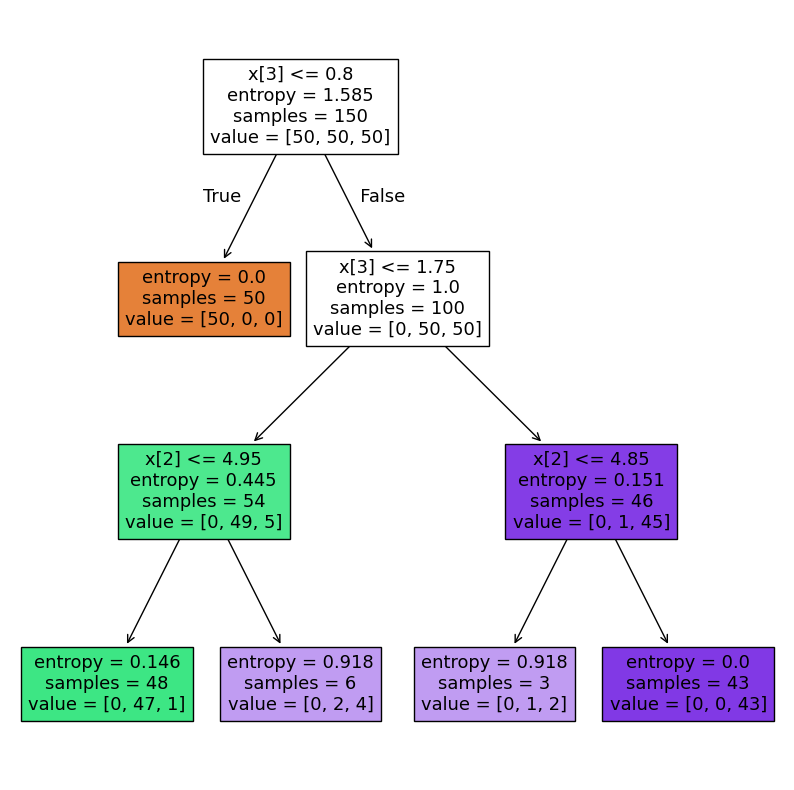

In [ ]:
plt.figure(figsize=(10, 10))
_ = tree.plot_tree(classifier,filled=True)

The last data point has class label = 2 for the Virginica species as shown below.

In [ ]:
df.tail(1)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
149,5.9,3.0,5.1,1.8,2,virginica


Let's create a new data point that is a slight modification of the last data point in the data set. We will use the classifier to predict this new (x,y) data point, which should have a label = 2.

In [ ]:
new_data_point = np.array([[6.0,3.1,5.1,1.8]])
print(new_data_point)

[[6.  3.1 5.1 1.8]]


In [ ]:
y_prediction = classifier.predict(new_data_point)
print(y_prediction)

[2]


The DT classifier correctly predicts the last data to be a Virginica species (label=2).

## Train and Test

Let's re-train the classifier by splitting the dataset into training and test sets.

#### Split data into training and testing sets

Split the dataset with 60% for training and 40% for testing.

Use the train_test_split function from the model_selection module.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=0, shuffle=True)

### Fit and Predict

Train the DT classifier on the training set.

In [ ]:
classifier = tree.DecisionTreeClassifier(criterion="entropy", max_depth=3)
classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

Predict class labels in the test set.

In [ ]:
y_prediction = classifier.predict(X_test)

Print the accuracy of the classifier.

In [ ]:
print("Accuracy: %.2f%%" % (classifier.score(X_test, y_test)*100))

Accuracy: 95.00%


Print the confusion matrix.

The confusion matrix is generated by running the classifier on the test set then constructing the True vs Predicted labels matrix elements using the labels from the test set.

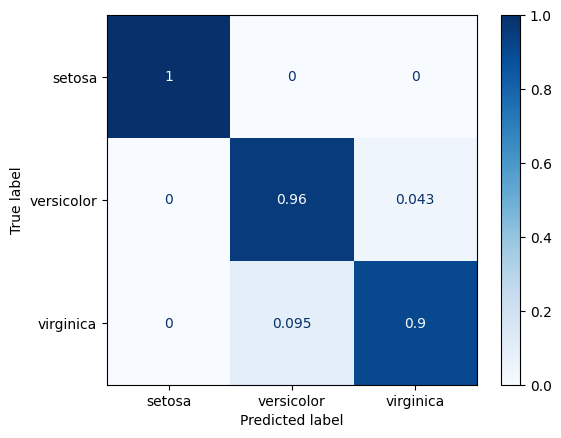

Accuracy: 95.00%


In [ ]:
plot_confusion_matrix(classifier, iris, X_test, y_test)


### Gathering Metrics

Review the classification metrics report.

In [ ]:
cl_report = metrics.classification_report(y_test, y_prediction, labels=np.unique(y_prediction), zero_division=1)
print("DT Classification Report:\n", cl_report)

DT Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.92      0.96      0.94        23
           2       0.95      0.90      0.93        21

    accuracy                           0.95        60
   macro avg       0.96      0.95      0.95        60
weighted avg       0.95      0.95      0.95        60



## Exercise

Improve the accuracy. Print out your new accuracy score.

In [ ]:
# DO NOT MODIFY THIS BLOCK
# BEGIN BLOCK
X_train = None
y_train = None
X_test = None
y_test = None
# END BLOCK

# Modify the remainder of this cell until the final accuracy printout.

# Reference data.
X = iris.data
y = iris.target

# Get classifier.
cl = tree.DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=0)

# Split data into testing and training sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42, shuffle=True)

# Fit and Predict.
cl.fit(X_train, y_train)
y_prediction = cl.predict(X_test);

# Accuracy.
print("Accuracy: %.2f%%" % (metrics.accuracy_score(y_test, y_prediction)*100))

Accuracy: 98.67%


## End of Excercise

## CMSC 478